# Nutrition5k: resultados de los jerárquicos

No entrena nada: lee los runs de `outputs/hierarchical/` (los escribe `02_experiments.ipynb` de esta carpeta) con las
funciones de `src/nutrition5k/results.py`. Elegir siempre por **validación** (`val_mean_pmae`); test se informa pero no
decide. `test_clean_mean_pmae` es el test oficial sin los platos de `data/nutrition5k/excluded_dishes.csv`.

In [1]:
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    # The clone made by 02_experiments.ipynb: outputs/ links to the volume and data/ holds the frames.
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().parent.name == "notebooks":
    os.chdir("../..")

import pandas as pd

from nutrition5k.results import (
    baseline_row, compare, cost, gallery, load_runs, seed_files, seed_groups, seed_spread, seed_table,
    seed_targets, select, steps, target_curves, target_table, test_metrics,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

FAMILY = "hierarchical"
SPLIT = "pilot"         # "full" o "pilot"
MODE = "complete"      # modo de frames a comparar

all_runs = load_runs([FAMILY], SPLIT, MODE)
assert len(all_runs), f"no runs of {FAMILY} in {SPLIT}; train them with 02_experiments.ipynb"
runs = select(all_runs)  # the recipe of the current runs; all_runs keeps every recipe
BASELINE = baseline_row(SPLIT)
print(f"{len(all_runs)} runs ({len(runs)} with the current recipe); baseline mean PMAE: "
      f"val {BASELINE['val_mean_pmae'].iloc[0]}, test {BASELINE['test_mean_pmae'].iloc[0]}")
runs

2 runs (2 with the current recipe); baseline mean PMAE: val 68.78185594884593, test 55.11396595533928


,run,path,family,backbone,recipe,unfreeze,heads,hidden,image_size,backbone_lr,seed,params_M,trainable_M,epochs_done,best_epoch,sec_per_epoch,gpu,gpu_memory_gb,status,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,val_total_mass_pmae,val_total_mass_mae,val_total_mass_rmse,val_total_mass_rsquared,val_total_calories_pmae,val_total_calories_mae,val_total_calories_rmse,val_total_calories_rsquared,val_total_fat_pmae,val_total_fat_mae,val_total_fat_rmse,val_total_fat_rsquared,val_total_carb_pmae,val_total_carb_mae,val_total_carb_rmse,val_total_carb_rsquared,val_total_protein_pmae,val_total_protein_mae,val_total_protein_rmse,val_total_protein_rsquared,test_total_mass_pmae,test_total_mass_mae,test_total_mass_rmse,test_total_mass_rsquared,test_total_calories_pmae,test_total_calories_mae,test_total_calories_rmse,test_total_calories_rsquared,test_total_fat_pmae,test_total_fat_mae,test_total_fat_rmse,test_total_fat_rsquared,test_total_carb_pmae,test_total_carb_mae,test_total_carb_rmse,test_total_carb_rsquared,test_total_protein_pmae,test_total_protein_mae,test_total_protein_rmse,test_total_protein_rsquared
1,swin_t-ft_all-single-h512-224-complete-pilot-f...,outputs/hierarchical/pilot/swin_t/swin_t-ft_al...,hierarchical,swin_t,fbn+clean,all,single,512,224,0.0001,0,28.045695,28.045695,3,2,18.256554,None,NaN,done,61.877818,59.066523,59.066523,51.971058,172.717148,215.286779,-0.090442,43.798039,113.127663,117.115676,0.340250,89.986045,13.781424,15.790718,0.241267,47.229768,7.565459,7.956830,-0.523648,76.404179,23.384584,26.255828,-0.659297,70.061419,80.658209,82.324573,-2.572454,50.689216,138.486884,183.082997,-0.389871,73.378563,13.852452,17.391222,-0.277789,44.974755,6.092752,7.598563,-0.227642,56.228659,8.075908,10.306434,-0.217353
0,convnext_t-ft_all-single-h512-224-complete-pil...,outputs/hierarchical/pilot/convnext_t/convnext...,hierarchical,convnext_t,fbn+clean,all,single,512,224,0.0001,0,28.346469,28.346469,3,2,15.884146,None,NaN,done,73.959123,60.897000,60.897000,70.319038,233.693604,298.981421,-1.103083,58.485470,151.064400,155.928957,-0.169506,90.634928,13.880801,18.721554,-0.066521,62.441096,10.002072,11.926406,-2.423131,87.915081,26.907659,31.593423,-1.402514,30.200569,34.768405,48.956632,-0.263370,54.574045,149.100538,194.572836,-0.569795,78.591575,14.836567,19.274916,-0.569581,72.418161,9.810524,10.925155,-1.537839,68.700651,9.867213,12.704175,-0.849664


## Etapa 1 (L1): arquitecturas (fine-tuning completo, cabeza `single`, 512, 224 px, lr del backbone 1e-4, semilla 0)

Resumen (`best_epoch` es la época con el menor `val_mean_pmae`, la que se guarda en `best.pt` y se evalúa), tabla de
validación con PMAE, MAE, RMSE y R² por objetivo (en verde el mejor de cada columna; MAE y RMSE en g o kcal), PMAE por
objetivo en barras y curvas de validación (el círculo grande marca la mejor época). La fila `baseline` es la línea
base de la media (predice la media de train para todos los platos) sobre la misma validación.

,run,status,epochs_done,best_epoch,val_mean_pmae,test_mean_pmae,test_clean_mean_pmae,params_M,trainable_M,sec_per_epoch,model
1,swin_t-ft_all-single-h512-224-complete-pilot-f...,done,3.0,2.0,61.877818,59.066523,59.066523,28.045695,28.045695,18.256554,swin_t ft all
0,convnext_t-ft_all-single-h512-224-complete-pil...,done,3.0,2.0,73.959123,60.897000,60.897000,28.346469,28.346469,15.884146,convnext_t ft all
0,average baseline,done,NaN,NaN,68.781856,55.113966,55.113966,0.000000,0.000000,NaN,baseline


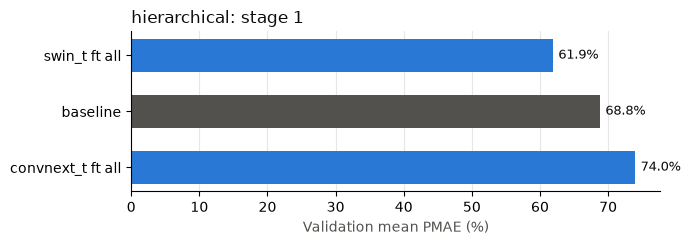

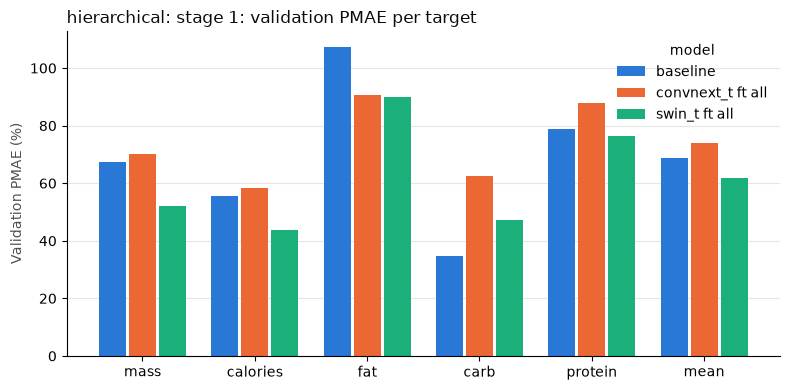

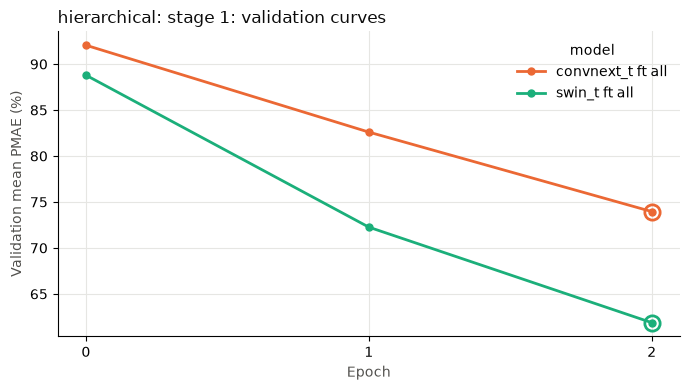

In [2]:
STAGE1 = dict(heads="single", hidden="512", image_size=224, backbone_lr=1e-4, seed=0)
stage1 = select(runs, unfreeze="all", **STAGE1)
stage1 = stage1.assign(model=stage1["backbone"] + " ft " + stage1["unfreeze"])
compare(stage1, "model", f"{FAMILY}: stage 1", baseline=BASELINE)

### Etapa 1: coste computacional

- `params_M`: parámetros en millones (backbone, tronco y cabezas). `size_MB`: tamaño de `best.pt` (float32).
- `MMACs`: millones de multiplicaciones-acumulaciones por imagen a la resolución del run; no depende del hardware.
- `cpu_ms`: latencia mediana de una imagen (batch 1) en la CPU de esta máquina, con pesos aleatorios. Solo compara
  backbones entre sí en la misma máquina; la latencia que cuenta es la del dispositivo.
- `gpu_memory_gb` y `sec_per_epoch`: pico de memoria de GPU y segundos por época **del entrenamiento**.

/home/abello/Desktop/harness-thesis-multimodal-health-ai/code/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


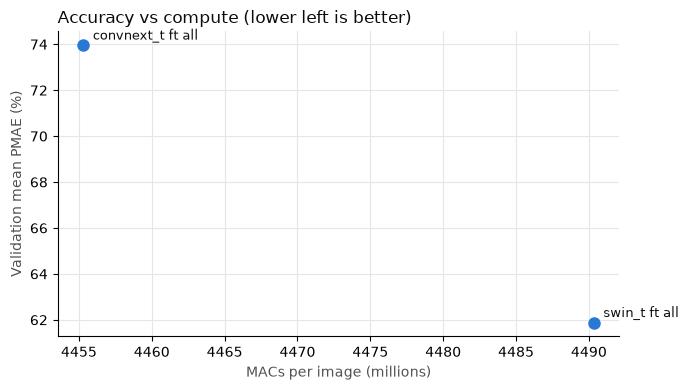

,family,val_mean_pmae,params_M,size_MB,MMACs,cpu_ms,gpu_memory_gb,sec_per_epoch,gpu
model,,,,,,,,,
swin_t ft all,hierarchical,61.877818,28.045695,112.242040,4490.324224,52.615335,NaN,18.256554,None
convnext_t ft all,hierarchical,73.959123,28.346469,113.446411,4455.288832,44.544060,NaN,15.884146,None


In [3]:
cost(stage1, "model")

## Etapa 2 (L2): ablaciones

Cada finalista sigue su propio camino greedy (mismos `BACKBONES` y `BEST_*` que en `02_experiments.ipynb`).
Cada paso compara el valor del factor dentro del backbone; menos de ~1 punto es empate.

In [4]:
BACKBONES = ("swin_t",)
BEST_UNFREEZE = {"swin_t": "2"}  # como texto, igual que en 02_experiments.ipynb

for backbone in BACKBONES:
    steps(runs, backbone, {
        "Step 1: fine-tuning depth": ("unfreeze", dict(heads="single", hidden="512", backbone_lr=1e-4, seed=0)),
        "Step 2: backbone learning rate": ("backbone_lr", dict(unfreeze=BEST_UNFREEZE[backbone], heads="single", hidden="512", seed=0)),
    })

swin_t - Step 1: fine-tuning depth
  nothing to compare yet
swin_t - Step 2: backbone learning rate
  nothing to compare yet


## Error por objetivo (test) de todas las ejecuciones terminadas

Ordenadas por validación. Solo se informa: no sirve para elegir.

In [5]:
target_table(runs[runs["status"] == "done"], "run", split="test")

## Evolución por objetivo de una ejecución

Comprueba si un objetivo empeora mientras la media mejora. La línea negra es la media; la vertical marca la época elegida.

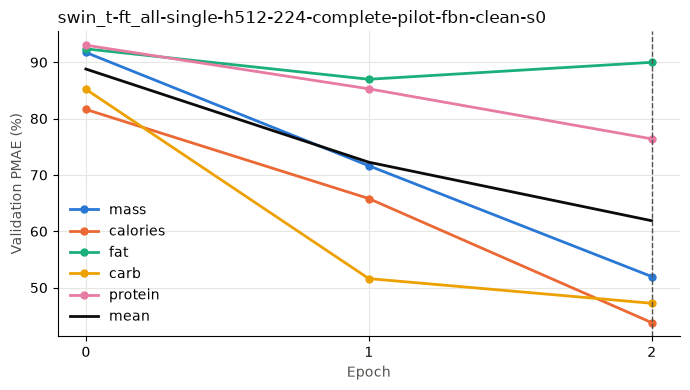

In [6]:
BEST = runs[runs["status"] == "done"].iloc[0]  # el mejor por validación; o all_runs[all_runs["run"] == "<nombre>"].iloc[0]
target_curves(BEST["path"])

## Etapa 3 (L3): media ± SD entre semillas

Una fila por configuración con más de una semilla; gráficas con el error de cada semilla (puntos) y la media ± SD.

In [7]:
seed_runs = seed_groups(runs)
if len(seed_runs):
    display(seed_table(seed_runs))
    seed_spread(seed_runs)
    seed_targets(seed_runs, "val")
    seed_targets(seed_runs, "test")
else:
    print("no configuration with more than one seed yet")

no configuration with more than one seed yet


## Métricas de test de los modelos finales

MAE, PMAE, RMSE y R² por objetivo, con la línea base como referencia. Por defecto, los tres mejores runs por
validación. Debajo, la media ± SD que escribe `train --all-seeds`.

In [8]:
FINAL = runs[runs["status"] == "done"].head(3)  # o select(runs, backbone=..., unfreeze=...)
test_metrics(FINAL, SPLIT).round(2)

unit     MAE  PMAE (%)    RMSE    R²
model                                              target                                        
swin_t-ft_all-single-h512-224-complete-pilot-fb... mass         g   80.66     70.06   82.32 -2.57
                                                   calories  kcal  138.49     50.69  183.08 -0.39
                                                   fat          g   13.85     73.38   17.39 -0.28
                                                   carb         g    6.09     44.97    7.60 -0.23
                                                   protein      g    8.08     56.23   10.31 -0.22
                                                   mean       NaN     NaN     59.07     NaN   NaN
convnext_t-ft_all-single-h512-224-complete-pilo... mass         g   34.77     30.20   48.96 -0.26
                                                   calories  kcal  149.10     54.57  194.57 -0.57
                                                   fat          g   14.84     78.59   19.27 -0.57
                                                   carb         g    9.81     72.42   10.93 -1.54
                                                   protein      g    9.87     68.70   12.70 -0.85
                                                   mean       NaN     NaN     60.90     NaN   NaN
average baseline                                   mass         g   67.98     59.05   79.36 -2.32
                                                   calories  kcal  143.70     52.60  159.45 -0.05
                                                   fat          g   14.16     74.99   16.25 -0.12
                                                   carb         g    5.13     37.83    7.06 -0.06
                                                   protein      g    7.34     51.10    9.73 -0.09
                                                   mean       NaN     NaN     55.11     NaN   NaN

In [9]:
seed_files(FAMILY, SPLIT, MODE)

""


## Galería de platos de test

Los platos con menor error, los de mayor error y algunos al azar de un run, con su primer frame, el valor real y
el predicho. Necesita los frames en `data/`.

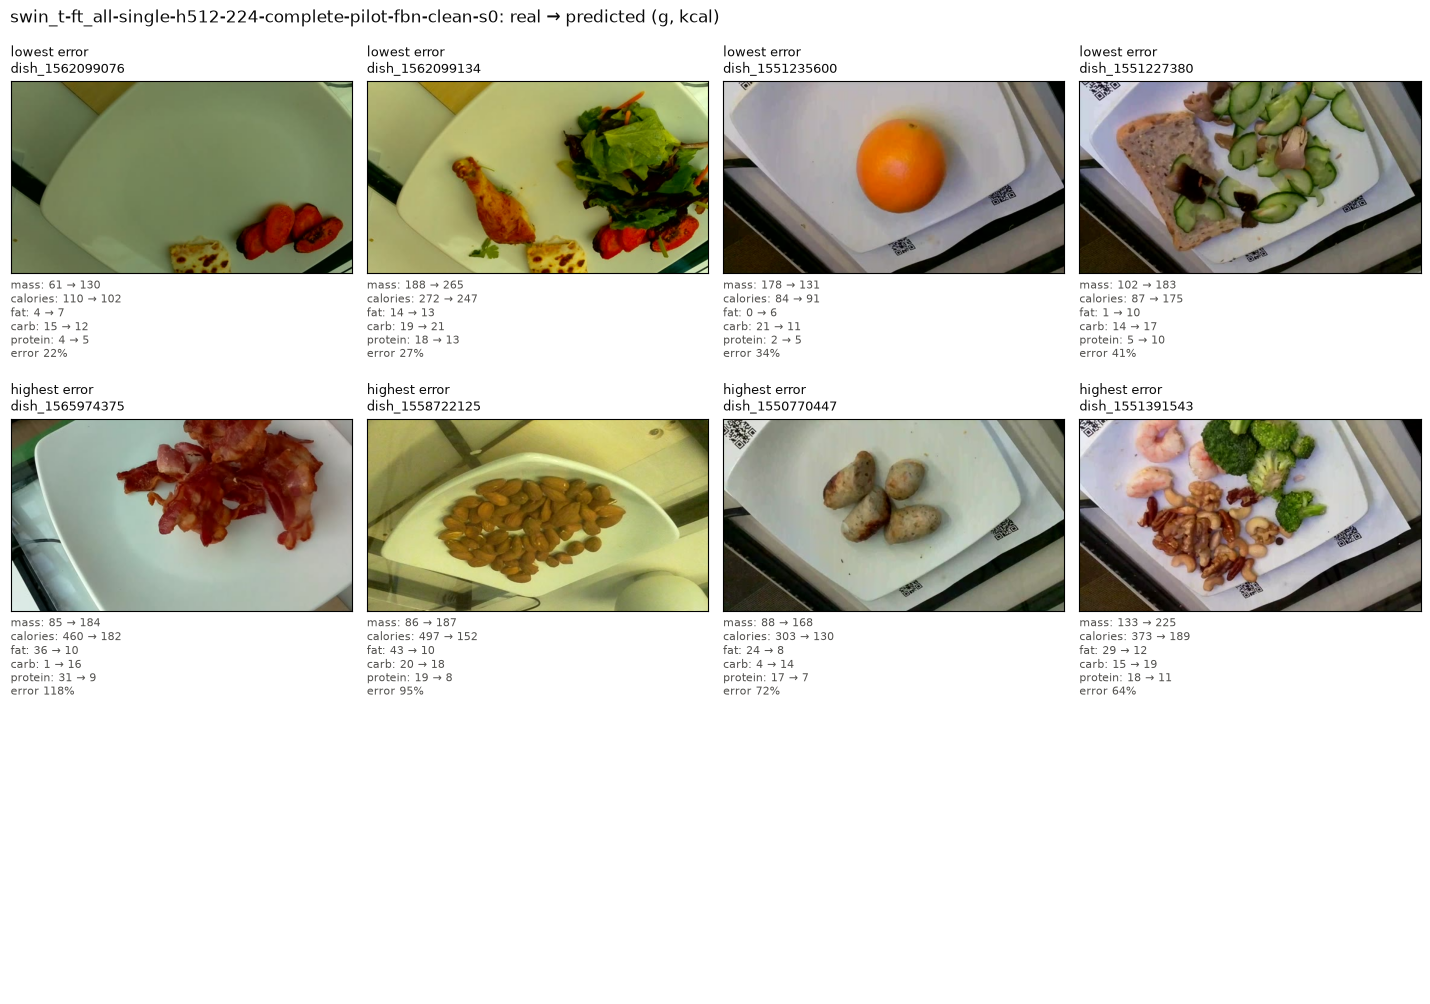

In [10]:
gallery(BEST["path"], SPLIT, MODE)